# Modelo KNN: utilidad de las parcelas de eucalipto

> Trabajo del modelo **KNN** dentro del proyecto de clasificación multiclase. Sigue la plantilla común de `docs/acuerdos.md` y los ADR del equipo.

- **Objetivo:** entrenar y evaluar un KNN comparable con los otros modelos, controlando el sobreajuste y dejando el pipeline guardado.
- **Datos:** `data/train.csv` y `data/val.csv`. **El conjunto de prueba no se lee**: se reserva para `06_conclusiones`.
- **Regla de las parcelas sin medidas:** ADR-0001. Si faltan las seis medidas (`Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm`), se responde `none` sin llamar al modelo.
- **Validación:** `StratifiedKFold` de 5 folds como esquema común y `StratifiedGroupKFold` por `Abbrev` como comprobación aparte (ADR-0002).

## 1. Carga de datos y preparación del pipeline

KNN clasifica por distancia, así que todas las variables deben estar en la misma escala: el preprocesado imputa con la mediana y estandariza las numéricas. La única categórica es `Abbrev` (el sitio), codificada con one-hot.

Se excluyen `Rep` y `PMCno` por ser identificadores y `Sp` porque tiene 25 especies con pocas parcelas cada una: en KNN añadiría 25 columnas dispersas que distorsionan las distancias (se comprueba con validación cruzada justo después del pipeline). Todo el preprocesado se ajusta **solo con train** dentro del `Pipeline`.

In [1]:
# Preparación para Google Colab (en local no hace nada): trae comun.py y data/ del repo
import os
import subprocess
import sys

if "google.colab" in sys.modules and not os.path.exists("comun.py"):
    carpeta = "/content/g3-Clasificacion-Multiclase"
    if not os.path.exists(carpeta):
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/IA-P1-BCN/g3-Clasificacion-Multiclase", carpeta],
            check=True,
        )
    os.chdir(carpeta)
    sys.path.insert(0, carpeta)
    # No se reinstala nada: Colab ya trae pandas, scikit-learn, scipy y matplotlib, y
    # cambiar un paquete ya cargado en el kernel rompe el import (hay que reiniciar).

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from comun import (
    CLASES,
    GAP_MAXIMO,
    NUMERICAS,
    SEMILLA,
    baseline_dummy,
    cargar_datos,
    conclusion_modelo,
    cv_comun,
    elegir_sin_sobreajuste,
    errores_frecuentes,
    evaluar_val,
    f1_por_fold,
    guardar_modelo,
    importancia_permutacion,
    mostrar_evaluacion,
    nivel_baseline,
    nivel_gap,
    predecir_con_regla,
    separar_xy,
    sin_medidas,
)

pd.set_option("display.max_columns", 30)

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** abre la caja de herramientas: trae las librerías que usaremos (pandas para las tablas, scikit-learn para el modelo, gráficos…).

**Qué encuentra:** nada que mostrar; solo deja todo listo y fija la semilla 42 para que los resultados se repitan igual.

**En cristiano:** antes de jugar, sacamos los juguetes de la caja.

In [2]:
train, val = cargar_datos()

conteo = pd.DataFrame({
    "train": train["Utility"].value_counts(),
    "validación": val["Utility"].value_counts(),
}).reindex(CLASES)

print(f"Entrenamiento: {train.shape[0]} filas | Validación: {val.shape[0]} filas")
display(conteo)

Entrenamiento: 469 filas | Validación: 110 filas


,train,validación
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** lee las tablas de entrenamiento (`train`) y de validación (`val`) y cuenta cuántas parcelas hay de cada clase.

**Qué encuentra:** 469 parcelas para entrenar y 110 para validar. En ambas la clase `good` es la más numerosa y `none`, `low` y `best` las más pequeñas.

**En cristiano:** tenemos un montón de fichas para aprender y otro montón aparte para el examen; comprobamos que en los dos hay de todos los tipos.

In [3]:
CATEGORICAS = ["Abbrev"]
VARIABLES = NUMERICAS + CATEGORICAS

X_train, y_train = separar_xy(train, VARIABLES)
X_val, y_val = separar_xy(val, VARIABLES)

print("Variables del modelo:", VARIABLES)
print("Excluidas:", [c for c in train.columns if c not in VARIABLES + ["Utility"]])


def crear_pipeline(numericas=NUMERICAS, categoricas=CATEGORICAS, **parametros_knn):
    preprocesado = ColumnTransformer([
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), numericas),
        ("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore")),
        ]), categoricas),
    ])
    return Pipeline([
        ("preprocesado", preprocesado),
        ("knn", KNeighborsClassifier(**parametros_knn)),
    ])

Variables del modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev']
Excluidas: ['Rep', 'Sp', 'PMCno']


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** elige con qué datos trabaja el modelo (medidas del árbol y el sitio) y monta la "cadena de montaje" (`Pipeline`): rellena huecos, pone todo en la misma escala y le da al KNN el resultado.

**Qué encuentra:** usa 9 variables y deja fuera `Rep`, `Sp` y `PMCno`.

**En cristiano:** KNN mide "a quién te pareces" con una regla. Si una medida va en metros y otra en kilómetros, la regla se vuelve loca; por eso primero las ponemos todas en la misma unidad.

### ¿Merece la pena cambiar las variables?

El preprocesado de arriba deja fuera `Sp` y usa las demás variables. Antes de afinar el modelo se comprueba con medidas (no solo con argumentos) si cambiar ese conjunto ayuda. Se compara el F1 macro de validación cruzada, con el mismo `StratifiedKFold` común y solo con train (la validación no participa en esta decisión), en tres conjuntos de variables y con dos valores de `k` (uno corto, 11, y uno largo, 41) para que la conclusión no dependa de un solo `k`:

- **actuales:** las 9 variables del modelo.
- **con `Sp`:** añade la especie (25 columnas one-hot muy dispersas).
- **sin `DBH` ni `Brnch_Fm`:** quita las dos variables con menos importancia al desordenarlas (sección 6), por si estorban en la distancia.

Regla: solo se cambia el conjunto si la mejora supera la desviación entre folds; si no, se mantiene el más simple.

In [4]:
CONJUNTOS = {
    "actuales (elegido)": (NUMERICAS, CATEGORICAS),
    "con Sp": (NUMERICAS, CATEGORICAS + ["Sp"]),
    "sin DBH ni Brnch_Fm": (
        [v for v in NUMERICAS if v not in ("DBH", "Brnch_Fm")],
        CATEGORICAS,
    ),
}

filas = []
for nombre, (numericas, categoricas) in CONJUNTOS.items():
    for k in (11, 41):
        puntuaciones = cross_val_score(
            crear_pipeline(numericas, categoricas, n_neighbors=k, p=1),
            train[numericas + categoricas],
            y_train,
            cv=cv_comun(),
            scoring="f1_macro",
            n_jobs=-1,
        )
        filas.append({
            "variables": nombre,
            "k": k,
            "F1 macro CV": puntuaciones.mean(),
            "desviación": puntuaciones.std(),
        })

display(pd.DataFrame(filas).round(3))

,variables,k,F1 macro CV,desviación
0,actuales (elegido),11,0.562,0.039
1,actuales (elegido),41,0.533,0.046
2,con Sp,11,0.544,0.045
3,con Sp,41,0.503,0.056
4,sin DBH ni Brnch_Fm,11,0.540,0.037
5,sin DBH ni Brnch_Fm,41,0.549,0.054


**Resultado:** se mantienen las 9 variables actuales y se sigue sin usar `Sp`.

- **Con `Sp`** el F1 macro baja con los dos valores de `k` (de 0,562 a 0,544 con `k = 11` y de 0,533 a 0,503 con `k = 41`). Son diferencias dentro de la desviación entre folds (≈ 0,04–0,06), pero van siempre en la misma dirección y añaden 25 columnas, así que no compensa.
- **Sin `DBH` ni `Brnch_Fm`** no hay mejora consistente: empeora con `k = 11` (0,540 frente a 0,562) y mejora algo con `k = 41` (0,549 frente a 0,533), también dentro del ruido. Según la regla fijada, una mejora que no supera la desviación no justifica cambiar el conjunto.
- **Cautela:** las dos variables débiles se eligieron mirando la importancia por permutación en validación (sección 6). Por eso la decisión se toma solo con esta comparación sobre train y no con esa importancia.

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** prueba tres "mochilas" de datos distintas (las que usamos, añadiendo la especie, y quitando dos medidas flojas) con la misma validación cruzada y dos valores de `k`.

**Qué encuentra:** ninguna mochila gana de forma clara a la actual. Con la especie baja siempre; sin `DBH` ni `Brnch_Fm` sube un poco con `k = 41` y baja con `k = 11`, todo dentro del ruido.

**En cristiano:** probamos si llevar más cosas o menos cosas en la mochila hacía correr mejor. Con la especie vamos peor, y quitar dos cosas pequeñas no cambia nada de verdad; nos quedamos con la mochila de siempre, que es la más sencilla.

## 2. Baseline: el mínimo a superar

Un baseline es un modelo "tonto" que sirve de suelo: un `DummyClassifier` que no mira los datos y responde siempre la clase más frecuente (`good`). Se mide igual que el KNN, con el mismo `StratifiedKFold` y con el mismo reparto de validación.

**Por qué importa:** una nota como "F1 macro = 0,55" no significa nada por sí sola. Con baseline se sabe cuántos puntos aporta el modelo sobre no hacer nada; sin él, no se puede decir si 0,55 es bueno o malo. Y con cinco clases desiguales la accuracy engaña: el Dummy acierta todas las `good` y ninguna de las demás, así que su accuracy parece decente mientras que su F1 macro (que da el mismo peso a las cinco clases) es muy bajo.

Se usa el mismo criterio que en `03_arbol_decision`: el baseline justo en validación es el Dummy **con** la regla del ADR-0001 (las parcelas sin medidas se predicen `none`), porque la regla ayuda a cualquier modelo. La escala de lectura es: menos de 10 puntos sobre el baseline = no supera; de 10 a 25 = supera poco; 25 o más = supera claramente.

In [5]:
DUMMY = baseline_dummy(X_train, y_train, X_val, y_val)

El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** mide a un "modelo tonto" que siempre contesta `good`, la clase más numerosa, con la misma validación cruzada que usaremos para el KNN, y repite el examen con las parcelas de validación (a las que no traen medidas se les pone `none` por regla, igual que al KNN).

**Qué encuentra:** en validación cruzada acierta el 32 % de las veces (accuracy 0,32) pero su F1 macro es solo 0,097. En validación saca 0,244 en toda la validación (sube porque acierta las 15 `none` sin medidas) y 0,101 solo con las parcelas medidas.

**Con baseline frente a sin baseline, en cristiano:** imagina que sacas un 5,5 en un examen.
- *Sin baseline* no sabes si es bueno o malo: ¿era un examen facilísimo o dificilísimo? Solo tienes tu nota.
- *Con baseline* sabes que alguien que contesta siempre lo mismo, sin leer las preguntas, saca un 1. Entonces tu 5,5 es muchísimo mejor que no saber nada, y además ves cuánto has ganado.

También avisa de una trampa: el 32 % de accuracy "parece" una nota decente, pero el modelo tonto solo acierta una clase de cinco. Por eso miramos F1 macro, que da el mismo peso a las cinco.

## 3. Validación cruzada y elección de hiperparámetros

Se ajustan `n_neighbors` (cuántos vecinos votan), `weights` (voto uniforme o ponderado por distancia) y `p` (distancia Manhattan o euclídea) con `GridSearchCV`, el `StratifiedKFold` común de 5 folds y F1 macro. Con `weights="distance"` el KNN se memoriza en train (cada parcela es su propio vecino a distancia 0), así que se espera un F1 de train de 1 y un gap grande; la rejilla lo deja a la vista.

Después se repite la validación agrupando por sitio con `StratifiedGroupKFold`: sirve para ver cuánto se inflan las métricas cuando el modelo ve parcelas del mismo sitio en train y validación (ADR-0002).

### Por qué esta rejilla

- **`n_neighbors` (cuántos vecinos votan):** pocos vecinos (3, 5…) dan un modelo muy sensible al ruido; muchos lo suavizan. Se prueba un rango amplio, de 3 a 101, para que el ganador no caiga en el borde de la rejilla.
- **`weights`:** `uniform` (todos los vecinos votan igual) o `distance` (los cercanos pesan más). Se prueban las dos porque `distance` suele puntuar bien en validación cruzada pero memoriza train.
- **`p`:** distancia Manhattan (1) o euclídea (2). Con variables escaladas y algunas discretas (`Vig`, `Surv`), Manhattan puede ir mejor; se deja que lo decida la validación cruzada.
- **Ampliación del rango de `k`:** una primera rejilla llegaba hasta `k = 31` y el ganador quedó justo en ese borde, así que se añadieron 41, 51, 71 y 101. Se hizo al ver también que el gap en validación quedaba cerca del límite; la elección final se sigue haciendo solo con validación cruzada sobre train, y el gap apenas cambió (de 5,5 a 5,4 puntos).
- **Regla de elección:** entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro (criterio de `docs/acuerdos.md`).

In [6]:
rejilla = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 71, 101],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
busqueda = GridSearchCV(
    crear_pipeline(),
    rejilla,
    scoring="f1_macro",
    cv=cv_comun(),
    return_train_score=True,
    n_jobs=-1,
    refit=elegir_sin_sobreajuste,
)
busqueda.fit(X_train, y_train)

tabla_cv = pd.DataFrame(busqueda.cv_results_)[[
    "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
    "mean_test_score", "std_test_score", "mean_train_score",
]]
tabla_cv.columns = [
    "k", "pesos", "p", "F1 macro validación (media)", "desviación", "F1 macro train (media)",
]
tabla_cv["gap CV (puntos)"] = (
    tabla_cv["F1 macro train (media)"] - tabla_cv["F1 macro validación (media)"]
) * 100
display(tabla_cv.sort_values("F1 macro validación (media)", ascending=False).head(10).round(3))

,k,pesos,p,F1 macro validación (media),desviación,F1 macro train (media),gap CV (puntos)
17,11,distance,1,0.571,0.061,1.000,42.949
15,9,distance,2,0.568,0.042,1.000,43.234
13,9,distance,1,0.568,0.059,1.000,43.237
12,9,uniform,1,0.564,0.052,0.673,10.915
16,11,uniform,1,0.562,0.039,0.648,8.559
18,11,uniform,2,0.562,0.022,0.648,8.593
19,11,distance,2,0.562,0.040,1.000,43.781
11,7,distance,2,0.562,0.041,1.000,43.805
25,21,distance,1,0.562,0.054,1.000,43.813
23,15,distance,2,0.562,0.044,1.000,43.847


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** prueba muchas combinaciones de ajustes del KNN (cuántos vecinos votan, si los cercanos pesan más, qué tipo de distancia) y las puntúa con validación cruzada.

**Qué encuentra:** una tabla con las mejores combinaciones. Las que dan nota 1,0 en train y bastante menos en validación son las de `weights="distance"`: se aprenden los ejemplos de memoria (gap de unos 43 puntos).

**En cristiano:** es como probar varias formas de estudiar. Algunas "memorizan el libro" y sacan 10 en los ejercicios conocidos, pero fallan en el examen.

### Elección con el criterio de overfitting

El acuerdo del grupo elige el modelo ganador entre los que tienen un gap menor de 5 puntos. Por eso no se queda sin más con el mejor F1 de la rejilla: se miran las combinaciones cuyo gap en CV es menor de 5 puntos y, de ellas, la de mayor F1 macro. Si ninguna cumple, se usa la de mayor F1 y se explica el gap.

In [7]:
cumplen = tabla_cv[tabla_cv["gap CV (puntos)"] < GAP_MAXIMO]
print(f"Combinaciones con gap CV < {GAP_MAXIMO} puntos: {len(cumplen)} de {len(tabla_cv)}")
display(cumplen.sort_values("F1 macro validación (media)", ascending=False).head(5).round(3))

mejor = busqueda.best_params_
PARAMETROS = {
    "n_neighbors": int(mejor["knn__n_neighbors"]),
    "weights": mejor["knn__weights"],
    "p": int(mejor["knn__p"]),
}
print("Hiperparámetros elegidos:", PARAMETROS)

Combinaciones con gap CV < 5 puntos: 8 de 48


,k,pesos,p,F1 macro validación (media),desviación,F1 macro train (media),gap CV (puntos)
32,41,uniform,1,0.533,0.046,0.555,2.125
28,31,uniform,1,0.532,0.048,0.572,3.987
34,41,uniform,2,0.523,0.061,0.557,3.449
38,51,uniform,2,0.485,0.054,0.523,3.760
40,71,uniform,1,0.452,0.047,0.463,1.069


Hiperparámetros elegidos: {'n_neighbors': 41, 'weights': 'uniform', 'p': 1}


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** de todas las combinaciones, se queda solo con las que no memorizan (diferencia train–validación en CV menor de 5 puntos) y elige la mejor de ellas.

**Qué encuentra:** 8 de 48 combinaciones cumplen. Gana `k = 41`, votos iguales y distancia Manhattan.

**En cristiano:** entre los alumnos que de verdad entienden la lección, escogemos al que mejor nota saca.

In [8]:
modelo_cv = crear_pipeline(**PARAMETROS)
cv = f1_por_fold(modelo_cv, X_train, y_train)

,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.546,0.579
2,0.581,0.461
3,0.580,0.433
4,0.487,0.657
5,0.473,0.333


StratifiedKFold: F1 macro = 0.533 ± 0.046 | gap 2.1 puntos ✅ correcto
Por sitio:       F1 macro = 0.492 ± 0.114 | gap 5.4 puntos


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** puntúa el modelo elegido de dos maneras: repartiendo las parcelas al azar (`StratifiedKFold`) y repartiéndolas por sitios, de modo que el sitio del examen no se haya visto al estudiar (`StratifiedGroupKFold`).

**Qué encuentra:** F1 macro de 0,533 ± 0,046 al azar y 0,492 ± 0,114 por sitios; con sitios la nota baja y varía mucho de un reparto a otro.

**En cristiano:** si ya conoces a los vecinos de la calle, adivinar es más fácil. Con un barrio nuevo cuesta más; esa es la nota más realista.

## 4. Métricas en validación

El modelo se reentrena con todo train. Antes de medir se aplica la regla del ADR-0001: las parcelas sin ninguna medida se predicen como `none`. Se informan las métricas sobre **toda** la validación y, aparte, solo sobre las parcelas **con medidas**, porque la regla acierta las primeras por construcción y no conviene mezclar ambas cosas.

In [9]:
modelo = crear_pipeline(**PARAMETROS).fit(X_train, y_train)
ev = evaluar_val(modelo, X_train, y_train, X_val, y_val, DUMMY)

sin_medidas_val = sin_medidas(X_val)
print(f"Parcelas sin medidas en validación (regla ADR-0001): {sin_medidas_val.sum()}")
print("Clases de esas parcelas:", y_val[sin_medidas_val].value_counts().to_dict())

Parcelas sin medidas en validación (regla ADR-0001): 15
Clases de esas parcelas: {'none': 15}


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** entrena el modelo con todo train y define cómo predecir: si una parcela no trae ninguna medida, se responde `none` sin preguntar al modelo (regla del ADR-0001).

**Qué encuentra:** en validación hay 15 parcelas sin medidas y todas son de verdad `none`.

**En cristiano:** si alguien llega con las manos vacías, ni miramos: sabemos que no ha traído nada.

1. MÉTRICAS EN VALIDACIÓN


,F1 macro,nivel F1,supera Dummy (puntos),nivel baseline,accuracy,accuracy balanceada,precision macro,recall macro,F1 ponderado
toda la validación,0.552,✅ aceptable,30.842,✅ supera claramente,0.645,0.565,0.630,0.565,0.608
solo con medidas,0.524,✅ aceptable,42.327,✅ supera claramente,0.589,0.528,0.616,0.528,0.544


2. OVERFITTING: F1 train 0.578 - F1 validación con medidas 0.524 = 5.4 puntos → ❌ ligero sobreajuste
3. MÉTRICAS POR CLASE


toda la validación                      solo con medidas               \
                 precision recall    f1 soporte        precision recall    f1   
none                  0.96   0.85  0.90    27.0             0.89   0.67  0.76   
low                   0.67   0.50  0.57    16.0             0.67   0.50  0.57   
average               0.45   0.47  0.46    19.0             0.45   0.47  0.46   
good                  0.58   0.94  0.71    32.0             0.58   0.94  0.71   
best                  0.50   0.06  0.11    16.0             0.50   0.06  0.11   

                 
        soporte  
none       12.0  
low        16.0  
average    19.0  
good       32.0  
best       16.0

4. MATRICES DE CONFUSIÓN


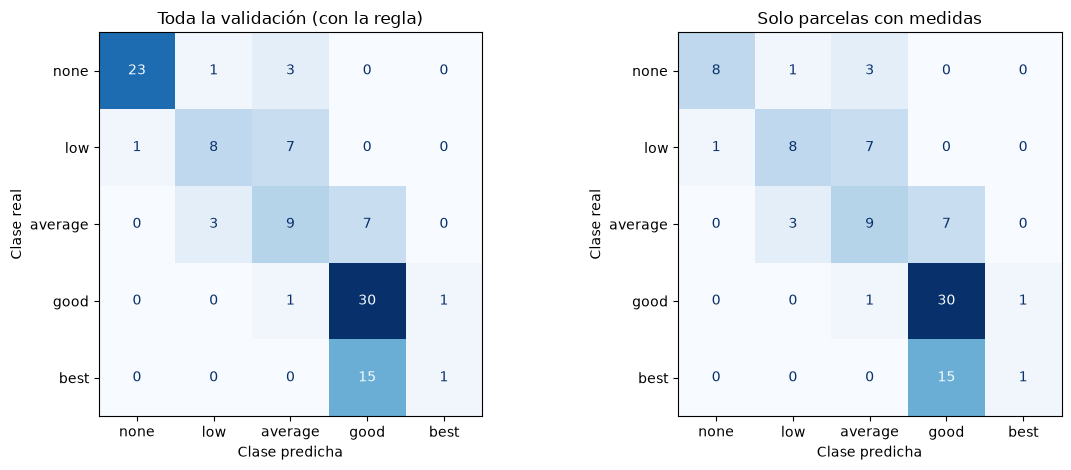

In [10]:
mostrar_evaluacion(ev)

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** saca la nota del examen (validación): aciertos totales (accuracy) y, por clase, cuántas veces acierta cuando dice "esta es X" (precision), cuántas X encuentra (recall) y su media (F1). Una tabla con las 110 parcelas y otra solo con las 95 medidas. Debajo dibuja las matrices de confusión: filas = lo que era de verdad, columnas = lo que dijo el modelo; la diagonal son los aciertos.

**Qué encuentra:** F1 macro 0,552 (completa) y 0,524 (solo medidas). `none` y `good` van bien; `best` casi nunca se encuentra (recall 0,06): de las 16 parcelas `best`, 15 se marcan como `good`, y `average` y `low` se mezclan con sus vecinas.

**En cristiano:** aprueba en lo corriente, pero cuando hay que reconocer a las parcelas "mejores" casi siempre se las pierde (como cuando dudas entre un notable y un sobresaliente).

## 5. Control de overfitting

El criterio del equipo es que la diferencia de **F1 macro** entre train y validación sea menor de **5 puntos**. Para que la regla fija del ADR-0001 no infle artificialmente la validación, el gap se mide **solo con las parcelas que tienen medidas**, que son las que realmente pasa por el modelo. Train ya no contiene parcelas sin medidas, así que es comparable.

In [11]:
medidas_val = ev["filas"]["solo con medidas"]
display(pd.DataFrame({
    "conjunto": [
        "train (modelo)",
        "validación completa (con regla)",
        "validación solo con medidas (modelo)",
    ],
    "F1 macro": [
        ev["f1_train"],
        ev["filas"]["toda la validación"]["F1 macro"],
        medidas_val["F1 macro"],
    ],
}).round(3))

print(f"Gap train - validación con medidas = {ev['gap']:.1f} puntos {nivel_gap(ev['gap'])}")
print(f"Cumple el criterio (< {GAP_MAXIMO} puntos):", "sí" if ev["cumple_gap"] else "no")

,conjunto,F1 macro
0,train (modelo),0.578
1,validación completa (con regla),0.552
2,validación solo con medidas (modelo),0.524


Gap train - validación con medidas = 5.4 puntos ❌ ligero sobreajuste
Cumple el criterio (< 5 puntos): no


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** compara la nota en las fichas de estudio (train) con la del examen (validación con medidas). El equipo exige que la diferencia sea menor de 5 puntos.

**Qué encuentra:** train 0,578 y validación 0,524: gap de 5,4 puntos, no cumple por 0,4. En CV era solo 2,1.

**En cristiano:** casi no ha hecho trampa, pero el margen se pasa por un pelo; el examen es pequeño (95 parcelas) y unas pocas respuestas lo mueven.

### Frente al baseline

Se pone el KNN al lado del Dummy con la misma vara: validación cruzada, validación completa (con la regla en ambos) y validación solo con parcelas medidas.

In [12]:
toda_val = ev["filas"]["toda la validación"]
comparacion = pd.DataFrame({
    "comparación": [
        "CV (train, StratifiedKFold)",
        "validación completa (con regla)",
        "validación solo con medidas",
    ],
    "F1 Dummy": [DUMMY["cv"], DUMMY["toda la validación"], DUMMY["solo con medidas"]],
    "F1 KNN": [cv["f1"], toda_val["F1 macro"], medidas_val["F1 macro"]],
})
comparacion["supera baseline (puntos)"] = (comparacion["F1 KNN"] - comparacion["F1 Dummy"]) * 100
comparacion["nivel baseline"] = comparacion["supera baseline (puntos)"].map(nivel_baseline)
display(comparacion.round(3))

,comparación,F1 Dummy,F1 KNN,supera baseline (puntos),nivel baseline
0,"CV (train, StratifiedKFold)",0.097,0.533,43.651,✅ supera claramente
1,validación completa (con regla),0.244,0.552,30.842,✅ supera claramente
2,validación solo con medidas,0.101,0.524,42.327,✅ supera claramente


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** pone al KNN y al tonto en la misma tabla y cuenta cuántos puntos de F1 le saca el KNN.

**Qué encuentra:** el KNN le gana por unos 44 puntos en validación cruzada, 31 en toda la validación y 42 solo con parcelas medidas; en los tres casos supera claramente al baseline (más de 25 puntos).

**En cristiano:** el KNN no es genial (le cuesta con las parcelas `best`), pero sí aprende cosas de verdad: saca de 4 a 5 veces más nota que el que contesta siempre lo mismo.

## 6. Interpretación: importancia de variables y errores

KNN no da una importancia nativa de variables, así que se usa `permutation_importance` sobre la validación **con medidas**: se mide cuánto cae el F1 macro al desordenar cada columna. Después se revisan los errores más frecuentes.

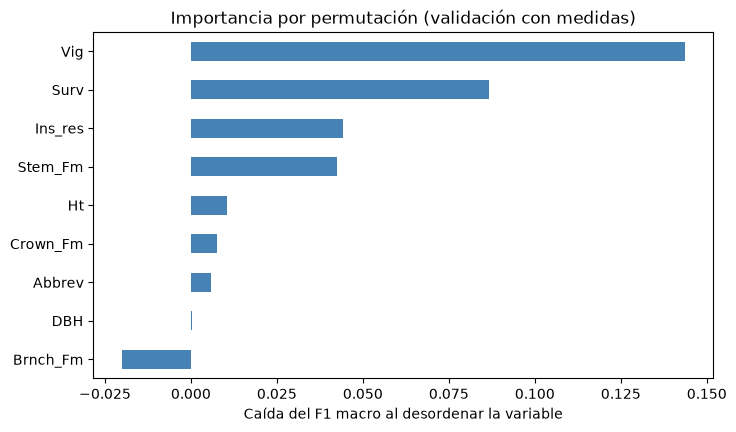

,importancia
Vig,0.144
Surv,0.087
Ins_res,0.044
Stem_Fm,0.043
Ht,0.010
Crown_Fm,0.007
Abbrev,0.006
DBH,0.000
Brnch_Fm,-0.020


In [13]:
importancia = importancia_permutacion(modelo, X_val, y_val)
display(importancia.sort_values(ascending=False).round(3).to_frame("importancia"))

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** estropea una columna cada vez (la baraja) y mira cuánto empeora el modelo. Cuanto más empeora, más importante era.

**Qué encuentra:** `Vig` (0,14) y `Surv` (0,09) son las que más importan; el resto casi no cuenta (`Brnch_Fm` sale negativa: ruido).

**En cristiano:** para saber si el vigor del árbol importa, se lo tapamos al modelo y vemos que se pierde mucho. Con otras columnas ni se nota.

In [14]:
pred_val = ev["pred"]
analisis = val.assign(predicha=pred_val)
analisis["error"] = analisis["Utility"] != analisis["predicha"]
errores = analisis[analisis["error"]]

display(errores_frecuentes(y_val, pred_val))

tasa_por_clase = analisis.groupby("Utility", observed=True).agg(
    n=("error", "size"), errores=("error", "sum")
)
tasa_por_clase["tasa de error"] = (tasa_por_clase["errores"] / tasa_por_clase["n"]).round(3)
display(tasa_por_clase.reindex(CLASES))

display(
    errores[["Abbrev", "Sp", "Vig", "Surv", "Ht", "DBH", "Utility", "predicha"]]
    .sort_values(["Utility", "predicha"])
    .head(20)
)

Errores: 39 de 110. Entre clases vecinas: 36; a 2 o más clases de distancia: 3.


,real,predicha,parcelas,distancia
0,best,good,15,1
1,low,average,7,1
2,average,good,7,1
3,average,low,3,1
4,none,average,3,2
5,none,low,1,1
6,low,none,1,1
7,good,average,1,1
8,good,best,1,1


,n,errores,tasa de error
Utility,,,
none,27,4,0.148
low,16,8,0.500
average,19,10,0.526
good,32,2,0.062
best,16,15,0.938


,Abbrev,Sp,Vig,Surv,Ht,DBH,Utility,predicha
23,Paw,nd,3.0,20.0,13.55,20.11,average,good
39,Puk,nd,3.0,100.0,7.84,16.30,average,good
50,WSh,re,3.8,25.0,8.84,22.34,average,good
65,WSp,ob,3.5,63.0,10.53,18.88,average,good
90,Lon,ov,3.0,100.0,5.57,14.53,average,good
108,WSp,fa,3.0,25.0,14.60,41.51,average,good
109,K83,fa,3.0,13.0,13.29,16.25,average,good
3,K81,si,3.0,25.0,4.27,3.56,average,low
30,K81a,ov,2.5,45.0,5.65,7.89,average,low
53,K81,br,3.0,88.0,4.11,4.62,average,low


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** lista los fallos: qué clase real se confundió con cuál, cuánto falla cada clase y ejemplos concretos.

**Qué encuentra:** 39 errores de 110 (35,5 %). El más repetido es `best` → `good` (15 veces); `best` falla el 94 % y `good` solo el 6 %.

**En cristiano:** el modelo se hace el "seguro" y dice `good` cuando duda, que es la respuesta más común; por eso acierta mucho `good` y pierde `best`.

### Observaciones de los errores

- La clase `best` casi no se acierta: 15 de 16 parcelas fallan (recall 0,06) y las 15 se predicen como `good`. Con k = 41 el voto de los vecinos lo ganan las clases mayoritarias del entorno (`good` es la más numerosa) y `best`, que es contigua y tiene pocas parcelas, queda siempre en minoría.
- Le siguen `average` (10 de 19) y `low` (8 de 16), que se confunden con sus clases vecinas (`good`/`low` y `average`). Todos los errores son saltos de una clase salvo unos pocos `none` ↔ `average`/`low`.
- `none` solo falla 4 veces porque la regla del ADR-0001 resuelve las 15 parcelas sin medidas; sobre las parcelas medidas su recall baja a 0,67.
- `Vig` y `Surv` son las únicas variables con importancia clara (0,14 y 0,09 de caída del F1). El resto está dentro del ruido (`Brnch_Fm` incluso sale negativa), lo que encaja con que KNN sufre cuando hay variables que no aportan: todas pesan igual en la distancia.

## 7. Guardar el pipeline y comprobar que se puede cargar

Se guarda el pipeline completo (preprocesado + KNN) con `joblib`, tal como pide el contrato de modelos. Después se carga desde disco y se predice sobre `data/val.csv` leído de nuevo, para comprobar que el artefacto es autónomo.

In [15]:
_ = guardar_modelo(modelo, "05_knn", X_val)

Guardado: models/05_knn.joblib (88.7 KB). ¿Al recargarlo predice igual? ✅


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** guarda el modelo entrenado (con su preprocesado) en el fichero `models/05_knn.joblib`.

**Qué encuentra:** un archivo de unos 89 KB.

**En cristiano:** metemos el cerebro ya aprendido en una cajita para usarlo otro día sin tener que volver a estudiar.

In [16]:
import joblib

_, val_fresco = cargar_datos()
modelo_cargado = joblib.load("models/05_knn.joblib")
pred_fresco = predecir_con_regla(modelo_cargado, val_fresco[VARIABLES])

print(f"Predicciones sobre data/val.csv: {len(pred_fresco)} filas")
display(pred_fresco.head().to_frame("predicha"))

Predicciones sobre data/val.csv: 110 filas


,predicha
0,none
1,good
2,good
3,low
4,good


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** abre la cajita en limpio, relee `data/val.csv` y comprueba que predice igual.

**Qué encuentra:** 110 predicciones y el mismo F1 macro de antes (0,552).

**En cristiano:** abrimos la caja y vemos que el cerebro sigue funcionando igual: está listo para la app.

### Requisitos y resumen común

`conclusion_modelo` comprueba los requisitos comunes del equipo, muestra el resumen y escribe `resultados/05_knn.json`, que lee `06_conclusiones`.

In [17]:
_ = conclusion_modelo("05_knn", cv, ev, DUMMY, PARAMETROS)

,requisito,fuente,resultado,cumple
id,,,,
R1,Multiclase (≥ 3 clases),Enunciado,5 clases,✅
R2,Overfitting < 5 puntos (train - validación con...,Enunciado,5.4 puntos,❌
R3,Supera claramente al Dummy (validación con med...,"Guía, paso 5",+42 puntos,✅
R4,Sin medidas → none por regla; métricas con y sin,ADR-0001,15 parcelas,✅
R5,StratifiedKFold + comprobación por sitio,ADR-0002,0.533 / 0.492,✅
R6,Pipeline guardado,Acuerdos,models/05_knn.joblib,✅


,validación cruzada,validación con regla,validación solo con medidas
F1 macro,0.533,0.552,0.524
gap (puntos),2.125,NaN,5.351
supera Dummy (puntos),43.651,30.842,42.327


Resultados guardados en resultados/05_knn.json


## 8. Conclusión

- **Modelo:** KNN con `k = 41`, voto uniforme y distancia Manhattan (`p = 1`), con imputación, estandarización y one-hot de `Abbrev`. Los hiperparámetros se eligen solo con train: entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro. No se toca el test.
- **Rendimiento:** F1 macro **0,552** en la validación completa y **0,524** solo con parcelas medidas (accuracy 0,645 y 0,589). Frente al baseline (`DummyClassifier`, que siempre responde `good`) supera claramente en los tres casos: +44 puntos en validación cruzada (0,533 frente a 0,097), +31 en toda la validación (0,552 frente a 0,244, ambos con la regla) y +42 con parcelas medidas (0,524 frente a 0,101). La comparación con los demás modelos se hace en `06_conclusiones`.
- **Overfitting:** el gap train − validación con medidas es **5,4 puntos**, así que **no cumple** el criterio de 5 puntos por 0,4. En validación cruzada el gap es de 2,1 puntos (train 0,555 frente a 0,533), por lo que el exceso se atribuye al ruido de una validación de solo 95 parcelas medidas (la desviación entre folds es de 4,6 puntos) y no a una memorización. No se ha retocado el modelo mirando la validación para forzar el cumplimiento. Con `weights="distance"` el gap sería de unos 43 puntos, y por eso se descarta.
- **Interpretación:** la señal viene de `Vig` y `Surv`; las demás variables no aportan de forma apreciable. Los errores se concentran en `best`, que se predice como `good` en 15 de 16 casos.
- **Comprobación por sitio:** el F1 macro con `StratifiedGroupKFold` (0,492 ± 0,114) es menor que con `StratifiedKFold` (0,533 ± 0,046), coherente con el ADR-0002: ver parcelas del mismo sitio ayuda y las métricas comunes están algo infladas; además la variabilidad entre folds es alta (de 0,33 a 0,66).
- **Límites:** un único reparto de validación, `best` con solo 16 parcelas y una rejilla corta de hiperparámetros. El test se evaluará una sola vez en `06_conclusiones`.